In [2]:
import os
import tensorflow
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, 
    roc_curve, roc_auc_score, RocCurveDisplay
)
from tensorflow.keras.callbacks import ModelCheckpoint
import tensorflow as tf
import keras
from tensorflow.keras import layers
from tensorflow.keras.models import Model
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.applications import ResNet50

ModuleNotFoundError: No module named 'tensorflow'

In [3]:
AUTOTUNE = tf.data.AUTOTUNE

csv_path = '/kaggle/input/datasets/ambarish/breakhis/Folds.csv'

img_dir = '/kaggle/input/datasets/ambarish/breakhis/BreaKHis_v1/'

data = pd.read_csv(csv_path)
class_names = ['benign', 'malignant']

print("دیتاست با موفقیت لود شد! تعداد کل سطرها:", len(data))
print(data.head(3))

NameError: name 'tf' is not defined

In [3]:
# استخراج برچسب‌ها از روی مسیر فایل
data['label'] = data['filename'].apply(lambda x: 'benign' if 'benign' in x else 'malignant')

In [4]:
data['patient_id'] = data['filename'].apply(
    lambda x: x.split('-')[0] + '-' + x.split('-')[1]
)
patients = data['patient_id'].unique()


In [5]:
print(data.columns)


Index(['fold', 'mag', 'grp', 'filename', 'label', 'patient_id'], dtype='object')


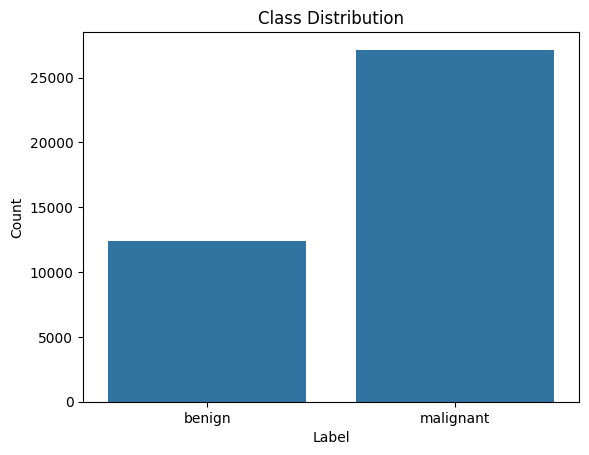

Count of Benign    : 12400
Count of Malignant : 27145


In [6]:
sns.countplot(data=data, x="label")

plt.title("Class Distribution")
plt.xlabel("Label")
plt.ylabel("Count")

plt.show()

# تعداد هر کلاس
print("Count of Benign    :", (data["label"] == "benign").sum())
print("Count of Malignant :", (data["label"] == "malignant").sum())

In [7]:
train_val_patients, test_patients = train_test_split(
    patients,
    test_size=0.15,
    random_state=42
)

# 2. جدا کردن train و validation
train_patients, valid_patients = train_test_split(
    train_val_patients,
    test_size=0.2,
    random_state=42
)


In [8]:
train_df = data[data['patient_id'].isin(train_patients)].reset_index(drop=True)
valid_df = data[data['patient_id'].isin(valid_patients)].reset_index(drop=True)
test_df  = data[data['patient_id'].isin(test_patients)].reset_index(drop=True)

In [9]:
print("\nSplit sizes:")
print("Train:", len(train_df))
print("Valid:", len(valid_df))
print("Test :", len(test_df))



Split sizes:
Train: 26840
Valid: 7295
Test : 5410


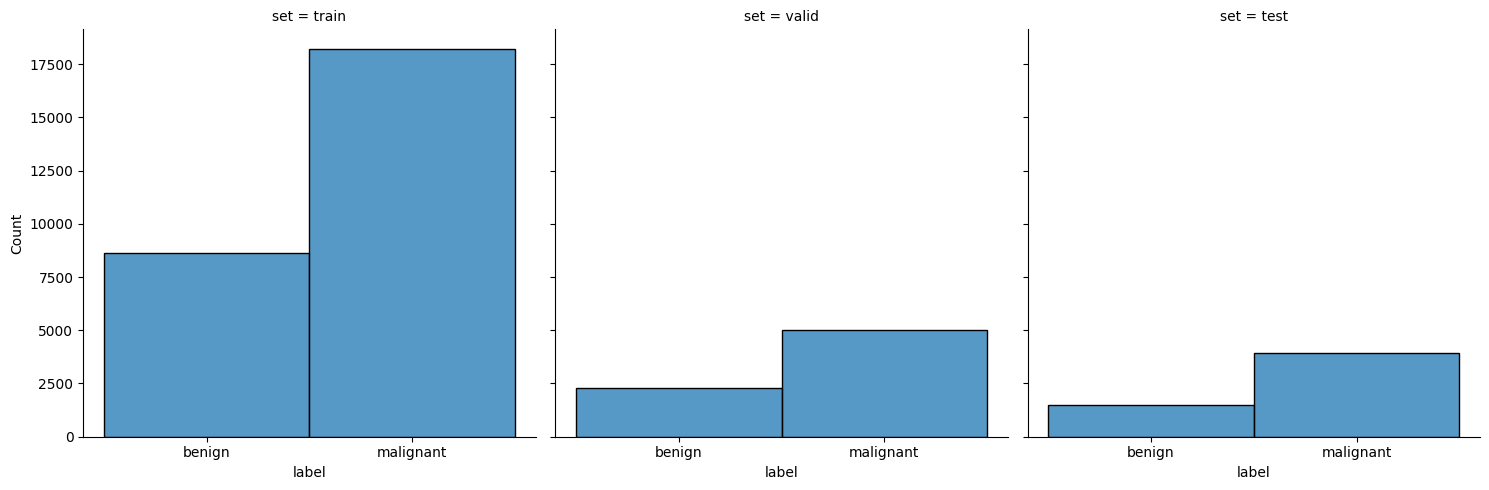

In [10]:
train_df['set'] = 'train'
valid_df['set'] = 'valid'
test_df['set'] = 'test'

data_new = pd.concat([train_df, valid_df, test_df], ignore_index=True)

import seaborn as sns

sns.displot(
    data=data_new,
    x='label',
    col='set'
)

In [11]:
#weights_path = '/kaggle/input/datasets/mehrshadlesani/resnet50-weight/RadImageNet-ResNet50_notop.h5'

In [12]:
# تعداد کل نمونه‌های بخش آموزش
total_train_samples = len(train_df)

# تعداد نمونه‌های هر کلاس
count_benign = len(train_df[train_df['label'] == 'benign'])
count_malignant = len(train_df[train_df['label'] == 'malignant'])

# فرمول استاندارد وزن‌دهی: total / (2 * class_count)
# دقت کن که ایندکس 0 برای benign و ایندکس 1 برای malignant است
class_weight_dict = {
    0: total_train_samples / (2.0 * count_benign),
    1: total_train_samples / (2.0 * count_malignant)
}

print("✅ وزن‌های محاسبه شده برای بالانس دیتای ترِین:")
print(class_weight_dict)

✅ وزن‌های محاسبه شده برای بالانس دیتای ترِین:
{0: 1.556844547563805, 1: 0.7365532381997805}


In [13]:
BATCH_SIZE = 24
IMG_SIZE = (224, 224)

# =========================
# TRAIN DATA (with augmentation)
# =========================
train_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input,
    rotation_range=45,
    width_shift_range=0.25,
    height_shift_range=0.25,
    zoom_range=0.4,
    shear_range=0.25,
    brightness_range=[0.6, 1.4],
    horizontal_flip=True,
    fill_mode='reflect'
)

train_generator = train_datagen.flow_from_dataframe(
    dataframe=train_df,
    directory=img_dir,
    x_col='filename',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

# =========================
# VALIDATION DATA (NO AUGMENTATION)
# =========================
valid_datagen = ImageDataGenerator(
    preprocessing_function=preprocess_input
)

valid_generator = valid_datagen.flow_from_dataframe(
    dataframe=valid_df,
    directory=img_dir,
    x_col='filename',
    y_col='label',
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

Found 26840 validated image filenames belonging to 2 classes.
Found 7295 validated image filenames belonging to 2 classes.


In [14]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50

base_model = ResNet50(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3),
    pooling="avg"
)

# Freeze
base_model.trainable = False

# Head model
inputs = keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)

# 🔥 Dense + Dropout (بهتر: قبل و بعد از activation)
x = layers.Dense(256)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.5)(x)   # ⬅️ Dropout اصلی

x = layers.Dense(128)(x)
x = layers.BatchNormalization()(x)
x = layers.Activation("relu")(x)
x = layers.Dropout(0.3)(x)   # ⬅️ Dropout دوم

outputs = layers.Dense(2, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")]
)

model.summary()

I0000 00:00:1781188257.751947      22 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1781188257.757883      22 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 2048)           │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,146,946 (92.11 MB)

 Trainable params: 558,466 (2.13 MB)

 Non-trainable params: 23,588,480 (89.98 MB)

In [15]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

import tensorflow as tf
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

print("\n--- آغاز فرآیند آموزش مدل روی کگل ---")

# =========================
# 1. ModelCheckpoint (بهینه‌تر)
# =========================
checkpoint_cb = ModelCheckpoint(
    filepath='breakhis_resnet50_best.keras',
    monitor='val_loss',
    save_best_only=True,
    save_weights_only=False,
    mode='min',
    verbose=1
)

# =========================
# 2. EarlyStopping (اصلاح‌شده)
# =========================
early_stopping_cb = EarlyStopping(
    monitor='val_loss',
    patience=5,   # کمی بیشتر از 3 برای stability
    mode='min',
    restore_best_weights=True,
    verbose=1
)

# =========================
# 3. Learning Rate Scheduler (خیلی مهم برای ResNet)
# =========================
reduce_lr_cb = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=1e-7,
    verbose=1
)

# =========================
# 4. Training
# =========================
history = model.fit(
    train_generator,
    steps_per_epoch=len(train_generator),
    epochs=20,   # 17 خیلی محدود بود
    validation_data=valid_generator,
    validation_steps=len(valid_generator),
    class_weight=class_weight_dict,
    callbacks=[
        checkpoint_cb,
        early_stopping_cb,
        reduce_lr_cb
    ]
)

# =========================
# 5. Save final model
# =========================
model.save('breakhis_resnet50_final.keras')

print("✅ مدل ResNet50 با موفقیت ذخیره شد!")


--- آغاز فرآیند آموزش مدل روی کگل ---


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20


I0000 00:00:1781188271.604282      70 service.cc:152] XLA service 0x7b8eb4013ac0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1781188271.604320      70 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1781188271.604323      70 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1781188273.655322      70 cuda_dnn.cc:529] Loaded cuDNN version 91002


   2/1119 ━━━━━━━━━━━━━━━━━━━━ 1:39 89ms/step - accuracy: 0.5208 - auc: 0.5827 - loss: 0.9455  

I0000 00:00:1781188279.528164      70 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


1119/1119 ━━━━━━━━━━━━━━━━━━━━ 0s 659ms/step - accuracy: 0.7145 - auc: 0.7877 - loss: 0.5777
Epoch 1: val_loss improved from inf to 0.30867, saving model to breakhis_resnet50_best.keras
1119/1119 ━━━━━━━━━━━━━━━━━━━━ 884s 776ms/step - accuracy: 0.7146 - auc: 0.7877 - loss: 0.5776 - val_accuracy: 0.8773 - val_auc: 0.9424 - val_loss: 0.3087 - learning_rate: 1.0000e-04
Epoch 2/20
1119/1119 ━━━━━━━━━━━━━━━━━━━━ 0s 598ms/step - accuracy: 0.8490 - auc: 0.9240 - loss: 0.3520
Epoch 2: val_loss improved from 0.30867 to 0.26870, saving model to breakhis_resnet50_best.keras
1119/1119 ━━━━━━━━━━━━━━━━━━━━ 771s 689ms/step - accuracy: 0.8490 - auc: 0.9240 - loss: 0.3520 - val_accuracy: 0.8992 - val_auc: 0.9559 - val_loss: 0.2687 - learning_rate: 1.0000e-04
Epoch 3/20
1119/1119 ━━━━━━━━━━━━━━━━━━━━ 0s 595ms/step - accuracy: 0.8758 - auc: 0.9458 - loss: 0.2945
Epoch 3: val_loss improved from 0.26870 to 0.24741, saving model to breakhis_resnet50_best.keras
1119/1119 ━━━━━━━━━━━━━━━━━━━━ 768s 687ms/step

In [16]:
# from tensorflow.keras.models import load_model

# # مسیر دقیق و قطعی مدل شما در کگل
# model_path = "/kaggle/input/notebooks/soroushgholami/brakehis1/breakhis_resnet50_best.keras"

# # بارگذاری مدل
# model = load_model(model_path)



In [17]:
# test_datagen = ImageDataGenerator(
#     preprocessing_function=preprocess_input  # اعمال همان پیش‌پردازش رزنیت
# )

# test_generator = test_datagen.flow_from_dataframe(
#     dataframe=test_df,
#     directory=img_dir,
#     x_col='filename',
#     y_col='label',
#     target_size=IMG_SIZE,
#     batch_size=BATCH_SIZE,
#     class_mode='categorical', # دقیقاً مشابه ترین و ولیدیشن
#     shuffle=False             # بسیار مهم: برای تست جابه‌جا نشود
# )

# # =========================
# # EVALUATE MODEL
# # =========================
# results = model.evaluate(test_generator, verbose=1)
# print("Loss and Accuracy on Test Set:", results)

In [18]:
# import numpy as np
# from sklearn.metrics import classification_report, confusion_matrix

# # ۱. گرفتن پیش‌بینی‌های مدل برای داده‌های تست
# predictions = model.predict(test_generator, verbose=1)
# # تبدیل احتمالات خروجی به لیبل‌های ۰ و ۱ (یا کلاس‌های نهایی)
# predicted_classes = np.argmax(predictions, axis=1)

# # ۲. گرفتن لیبل‌های واقعی از ژنراتور
# true_classes = test_generator.classes
# class_labels = list(test_generator.class_indices.keys())

# # ۳. چاپ گزارش طبقه‌بندی (Precision, Recall, F1-Score)
# print("Classification Report:")
# print(classification_report(true_classes, predicted_classes, target_names=class_labels))

# # ۴. چاپ ماتریس آشفتگی
# print("Confusion Matrix:")
# print(confusion_matrix(true_classes, predicted_classes))

In [19]:
# from sklearn.metrics import roc_auc_score
# import numpy as np

# # پیش‌بینی احتمال‌ها
# y_pred = model.predict(test_generator, verbose=1)

# # برچسب‌های واقعی
# y_true = test_generator.classes

# # چون class_mode='categorical' است و دو کلاس داری
# auc = roc_auc_score(y_true, y_pred[:, 1])

#print("Test ROC-AUC:", auc)